In [8]:
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn 
from torch.utils.data import DataLoader, Subset

from src.dataset import LOLv2Dataset
from src.models.direct_cnn import DirectCNN

In [9]:
# test data pipeline batch
ROOT = "./dataset/LOL-v2/Real_captured"

train_dataset = LOLv2Dataset(
    root=ROOT,
    split="Train",
    patch_size=256,
    augment=True
)

test_dataset = LOLv2Dataset(
    root=ROOT,
    split="Test",
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

# Batch size 1 avoids issues if test image sizes differ
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

# Inspect one batch
low, normal = next(iter(train_loader))

print("Low shape:", low.shape)
print("Normal shape:", normal.shape)

print("Low range:", low.min().item(), low.max().item())
print("Normal range:", normal.min().item(), normal.max().item())

Train: 689 image pairs loaded
Test: 100 image pairs loaded
Low shape: torch.Size([8, 3, 256, 256])
Normal shape: torch.Size([8, 3, 256, 256])
Low range: 0.0 0.7647058963775635
Normal range: 0.0 1.0


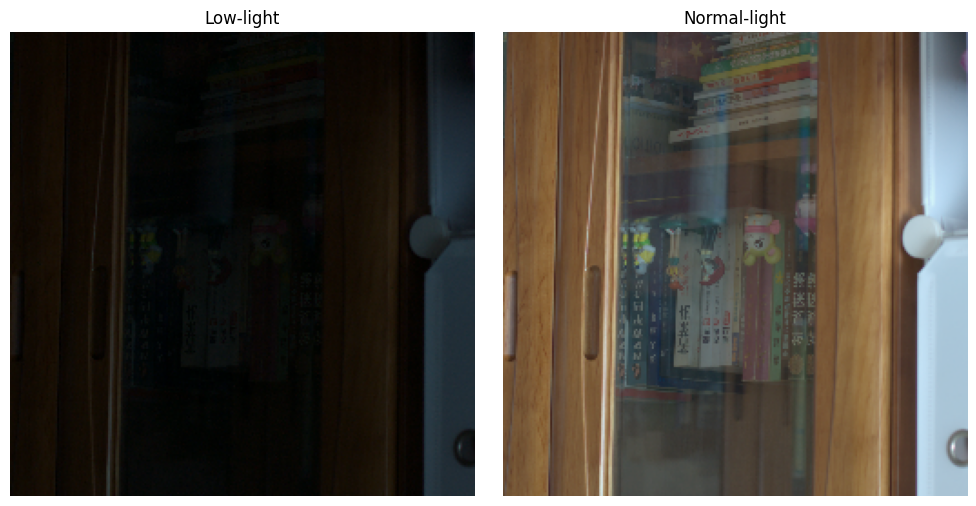

In [10]:
# visualize 1 set of images
low, normal = train_dataset[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(low.permute(1, 2, 0))
axes[0].set_title("Low-light")

axes[1].imshow(normal.permute(1, 2, 0))
axes[1].set_title("Normal-light")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# test 1 small set to CNN model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

dataset = LOLv2Dataset(
    root=ROOT,
    split="train",
    augment=False
)

small_dataset = Subset(dataset, range(8))
loader = DataLoader(
    small_dataset,
    batch_size=1,
    shuffle=True,
)

model = DirectCNN().to(device)
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)
epochs = 50

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for low, normal in loader:
        low = low.to(device)
        normal = normal.to(device)

        # forward pass
        output = model(low)
        loss = criterion(output, normal)

        # backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(loader)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.6f}"
    )

train: 689 image pairs loaded
Epoch [1/50] Loss: 0.214042
Epoch [2/50] Loss: 0.211852
Epoch [3/50] Loss: 0.209173
Epoch [4/50] Loss: 0.203967
Epoch [5/50] Loss: 0.196227
Epoch [6/50] Loss: 0.186648
Epoch [7/50] Loss: 0.172450
Epoch [8/50] Loss: 0.157534
Epoch [9/50] Loss: 0.144143
Epoch [10/50] Loss: 0.137172
Epoch [11/50] Loss: 0.132934
Epoch [12/50] Loss: 0.131381
Epoch [13/50] Loss: 0.130418
Epoch [14/50] Loss: 0.133393
Epoch [15/50] Loss: 0.130200
Epoch [16/50] Loss: 0.131553
Epoch [17/50] Loss: 0.129143
Epoch [18/50] Loss: 0.130064
Epoch [19/50] Loss: 0.127658
Epoch [20/50] Loss: 0.133083
Epoch [21/50] Loss: 0.127337
Epoch [22/50] Loss: 0.127396
Epoch [23/50] Loss: 0.128013
Epoch [24/50] Loss: 0.128406
Epoch [25/50] Loss: 0.127091
Epoch [26/50] Loss: 0.126505
Epoch [27/50] Loss: 0.126897
Epoch [28/50] Loss: 0.128079
Epoch [29/50] Loss: 0.126915
Epoch [30/50] Loss: 0.129170
Epoch [31/50] Loss: 0.127617
Epoch [32/50] Loss: 0.126455
Epoch [33/50] Loss: 0.126029
Epoch [34/50] Loss: 0.

Output shape: torch.Size([3, 400, 600])


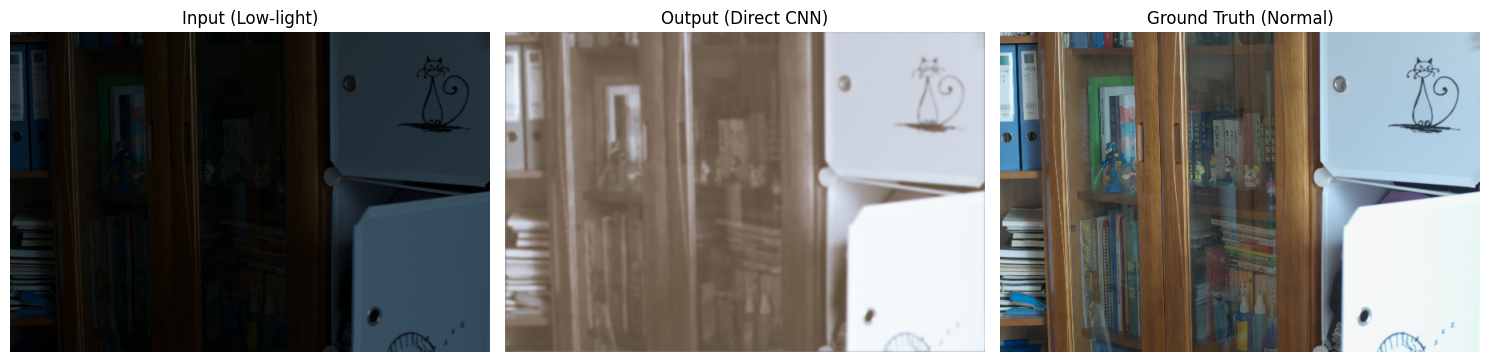

In [16]:
# visualize the output
model.eval()

low, normal = dataset[0]
low_input = low.unsqueeze(0).to(device) # return batch dimension: (3, H, W) -> (1, 3, H, W)
# Inference
with torch.no_grad():
    output = model(low_input)

# Remove batch dimension and move to CPU
output = output.squeeze(0).cpu()

print("Output shape:", output.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    low,
    output,
    normal
]

titles = [
    "Input (Low-light)",
    "Output (Direct CNN)",
    "Ground Truth (Normal)"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()